# Google's geo experiment playbook, tested on ten years of real Iowa sales

Independent rebuild of **Meridian GeoX** (Ye, Sinn, Li, Jiao, Google, 2026):
[paper](https://research.google/pubs/pub1090193/), [code](https://github.com/google/meridian-geox).

Hypotheses and pass/fail rules were committed before any analysis (`PREREGISTRATION.md`).
Nothing here uses the GeoX library itself: everything is reimplemented from the paper so each step is visible.

**Assumptions** (numbered, used throughout)
1. Data: Iowa Liquor Sales, the state's open data (retailer purchases from the state wholesaler), summed to weekly dollars by county. Real geos, real noise.
2. A study is a 50-week window: 26 train, 8 validation, 8 evaluation, 8 test weeks. Windows start every 8 weeks. Counties with any empty week in a window are dropped from it.
3. One treatment cell holding 25% to 35% of the window's sales (the paper's single-cell setup uses 30%).
4. Design-time numbers never touch the test weeks. Design MDE: model fit on train, RMSE on validation, placebo effects on evaluation. Analysis: model fit on train + validation, RMSE on evaluation, effect on test. This is a simplification of GeoX's workflow that keeps every quantity out of sample.
5. alpha = 0.10 two-sided, power 80% (the paper's settings). MDE = SE x (z_0.95 + z_0.80) / baseline.
6. Lifts are injected by multiplying the treated counties' test-week sales, so the true effect is known exactly.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, os, time
from scipy import stats
from scipy.optimize import nnls
from sklearn.cluster import KMeans
from multiprocessing import Pool

os.makedirs("figures", exist_ok=True)
Z_MDE = stats.norm.ppf(0.95) + stats.norm.ppf(0.80)
TR, VA, EV, TE = 26, 8, 8, 8
WIN = TR + VA + EV + TE
I_TR = np.arange(0, TR); I_VA = np.arange(TR, TR + VA); I_EV = np.arange(TR + VA, TR + VA + EV); I_TE = np.arange(TR + VA + EV, WIN)
I_TRVA = np.arange(0, TR + VA)
N_CAND, N_PLAC_CAND, N_PLAC, N_AA = 2000, 600, 200, 100
RELAXED = []

def load_weekly():
    path = "iowa_weekly_county.parquet"
    if os.path.exists(path):
        return pd.read_parquet(path)
    raise FileNotFoundError("Run the data cell in the README to build iowa_weekly_county.parquet")

W = load_weekly()
print(W.shape, W.index.min().date(), W.index.max().date())

(548, 99) 2012-01-09 2022-07-04


## Building blocks: TBR, synthetic control, SDID, stratified sampling, placebos

In [2]:
def gmean(Y, M):
    """Average series of the geos in each mask. Y: T x G, M: K x G (0/1). Returns K x T."""
    return (M @ Y.T) / M.sum(1, keepdims=True)

def tbr_fit(yt, yc, idx):
    """Time-based regression yt = a + b*yc on weeks idx, b >= 0. yt, yc: K x T."""
    xt, xc = yt[:, idx], yc[:, idx]
    mc, mt = xc.mean(1, keepdims=True), xt.mean(1, keepdims=True)
    b = ((xc - mc) * (xt - mt)).sum(1, keepdims=True) / ((xc - mc) ** 2).sum(1, keepdims=True)
    b = np.maximum(b, 0)
    a = mt - b * mc
    return a, b

def tbr_stats(yt, yc, fit_idx, rmse_idx, eff_idx):
    a, b = tbr_fit(yt, yc, fit_idx)
    res = yt - (a + b * yc)
    rmse = np.sqrt((res[:, rmse_idx] ** 2).mean(1))
    eff = res[:, eff_idx].sum(1)
    return eff, rmse, res

def r2_val(yt, yc):
    a, b = tbr_fit(yt, yc, I_TR)
    pred = a + b * yc
    ss = ((yt[:, I_VA] - pred[:, I_VA]) ** 2).sum(1)
    st = ((yt[:, I_VA] - yt[:, I_VA].mean(1, keepdims=True)) ** 2).sum(1)
    return 1 - ss / st

def _simplex_nnls(A, y, ridge=0.0, big=1e3):
    """min ||A w - y||^2 + ridge ||w||^2, w >= 0, sum w = 1 (augmented NNLS)."""
    k = A.shape[1]
    rows = [A, big * np.ones((1, k))]
    rhs = [y, [big]]
    if ridge > 0:
        rows.insert(1, np.sqrt(ridge) * np.eye(k)); rhs.insert(1, np.zeros(k))
    w, _ = nnls(np.vstack(rows), np.concatenate(rhs), maxiter=50 * k)
    return w

def sc_counterfactual(yt, Yd, fit_idx):
    """Synthetic control: convex weights on donor geos. yt: T, Yd: T x J."""
    s = yt[fit_idx].std() + 1e-9
    w = _simplex_nnls(Yd[fit_idx] / s, yt[fit_idx] / s)
    return Yd @ w

def sdid_counterfactual(yt, Yd, fit_idx, post_idx, n_treated):
    """Synthetic DiD (Arkhangelsky et al. 2021): unit weights with intercept + ridge, time weights with intercept."""
    s = yt[fit_idx].std() + 1e-9
    yt_, Yd_ = yt / s, Yd / s
    pre = Yd_[fit_idx]
    sigma = np.diff(pre, axis=0).std()
    zeta2 = (n_treated * len(post_idx)) ** 0.5 * sigma ** 2
    yc = yt_[fit_idx] - yt_[fit_idx].mean(); Xc = pre - pre.mean(0)
    w = _simplex_nnls(Xc, yc, ridge=zeta2 * len(fit_idx))
    post_mean = Yd_[post_idx].mean(0)
    Xt = pre.T - pre.T.mean(0); yp = post_mean - post_mean.mean()
    lam = _simplex_nnls(Xt, yp, ridge=1e-6 * sigma ** 2 * len(post_idx))
    synth = Yd_ @ w
    offset = lam @ (yt_[fit_idx] - synth[fit_idx])
    return (synth + offset) * s

def est_stats(method, Y, tmask, cmask, fit_idx, rmse_idx, eff_idx):
    """Effect and RMSE for one design under SC or SDID. tmask/cmask: boolean G."""
    yt = Y[:, tmask].mean(1); Yd = Y[:, cmask]
    if method == "sc":
        cf = sc_counterfactual(yt, Yd, fit_idx)
    else:
        cf = sdid_counterfactual(yt, Yd, fit_idx, eff_idx, int(tmask.sum()))
    res = yt - cf
    return res[eff_idx].sum(), np.sqrt((res[rmse_idx] ** 2).mean())

def dtw(a, b):
    n, m = len(a), len(b)
    D = np.full((n + 1, m + 1), np.inf); D[0, 0] = 0
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = abs(a[i - 1] - b[j - 1]) + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    return D[n, m]

def strata(Ytr, k=4, seed=0):
    """Paper Sec 3.1: k-means on mean, CV, slope, lag-1 autocorrelation, DTW distance to the average series."""
    T = Ytr.shape[0]; t = np.arange(T)
    mean = Ytr.mean(0); cv = Ytr.std(0, ddof=1) / mean
    slope = np.polyfit(t, Ytr, 1)[0]
    dm = Ytr - mean
    ac1 = (dm[:-1] * dm[1:]).sum(0) / (dm ** 2).sum(0)
    ref = Ytr.mean(1)
    d = np.array([dtw(Ytr[:, g], ref) for g in range(Ytr.shape[1])])
    F = np.column_stack([mean, cv, slope, ac1, d])
    F = (F - F.mean(0)) / (F.std(0) + 1e-12)
    return KMeans(k, n_init=10, random_state=seed).fit_predict(F)

def gen_masks(rule, share, labels, n, rng, lo=0.25, hi=0.35, frac=0.30):
    """Draw n treatment masks meeting the share constraint. rule: 'random' (Bernoulli) or 'stratified'."""
    G = len(share); out = []; tries = 0
    while sum(len(o) for o in out) < n:
        tries += 1
        if tries % 20 == 0:          # Deviation 1: widen an infeasible share range (logged)
            lo, hi = lo - 0.05, hi + 0.05; RELAXED.append((round(lo, 2), round(hi, 2)))
        B = 4 * n
        if rule == "random":
            M = rng.random((B, G)) < frac
        else:
            M = np.zeros((B, G), bool)
            for s in np.unique(labels):
                idx = np.where(labels == s)[0]; ns = len(idx)
                base = int(np.floor(frac * ns)); extra = rng.random(B) < (frac * ns - base)
                kk = base + extra
                order = np.argsort(rng.random((B, ns)), axis=1)
                rank = np.empty_like(order); np.put_along_axis(rank, order, np.arange(ns)[None, :].repeat(B, 0), axis=1)
                M[:, idx] = rank < kk[:, None]
        sh = M @ share
        ok = (sh >= lo) & (sh <= hi) & (M.sum(1) >= 2) & ((~M).sum(1) >= 2)
        out.append(M[ok])
    return np.vstack(out)[:n].astype(float)

def placebos(Y, tmask, rule, labels, rng, design_aware=True):
    """Placebo-treated sets drawn from the control pool only. Returns (placebo-treated masks, placebo-control masks) over all G."""
    G = Y.shape[1]; pool = np.where(tmask == 0)[0]
    Yp = Y[:, pool]
    if design_aware:
        share = Yp[I_TR].sum(0) / Yp[I_TR].sum()
        cand = gen_masks(rule, share, labels[pool], N_PLAC_CAND, rng)
        yt, yc = gmean(Yp, cand), gmean(Yp, 1 - cand)
        r2 = r2_val(yt, yc)
        if design_aware == "matched":     # exploratory: same selection strength as the A/A designs (R2 >= 0.8, drawn at random)
            ok = np.where(r2 >= 0.8)[0]
            order = rng.choice(ok, min(N_PLAC, len(ok)), replace=False) if len(ok) >= 20 else np.argsort(-r2)[:20]
        else:                              # pre-registered: R2 >= 0.6, top 200 by R2 (GeoX's default rule)
            keep = r2 >= 0.6
            if keep.sum() < 20: keep = r2 >= np.sort(r2)[-20]
            order = np.argsort(-r2 * keep)[: min(N_PLAC, keep.sum())]
        sub = cand[order]
    else:
        k = int(tmask.sum())
        sub = np.zeros((N_PLAC, len(pool)))
        for i in range(N_PLAC):
            sub[i, rng.choice(len(pool), k, replace=False)] = 1
    PT = np.zeros((len(sub), G)); PT[:, pool] = sub
    PC = np.zeros((len(sub), G)); PC[:, pool] = 1 - sub
    return PT, PC

def placebo_test(t_obs, t_plac):
    """Two-sided empirical p-value (paper eq. 12) and studentized SD."""
    p = (1 + np.sum(np.abs(t_plac) >= abs(t_obs))) / (1 + len(t_plac))
    return p, t_plac.std(ddof=1)

def design_windows():
    return dict(fit=I_TR, rmse=I_VA, eff=I_EV)

def analysis_windows():
    return dict(fit=I_TRVA, rmse=I_EV, eff=I_TE)

## One study, end to end
Design search (both rules), the chosen design's analysis with injected lifts, 100 A/A designs for the false-positive test,
and the estimator comparison (TBR, SC, SDID) on the top stratified designs.

In [3]:
def tbr_placebo_stats(Y, PT, PC, win):
    yt, yc = gmean(Y, PT), gmean(Y, PC)
    eff, rmse, _ = tbr_stats(yt, yc, win["fit"], win["rmse"], win["eff"])
    return eff / rmse

def design_mde_tbr(Y, tm, PT, PC):
    """Design-time MDE (relative) for one design using a given placebo set."""
    w = design_windows()
    yt, yc = gmean(Y, tm[None]), gmean(Y, 1 - tm[None])
    eff, rmse, _ = tbr_stats(yt, yc, w["fit"], w["rmse"], w["eff"])
    t_pl = tbr_placebo_stats(Y, PT, PC, w)
    se = t_pl.std(ddof=1) * rmse[0]
    base = yt[0, w["eff"]].sum()
    return se * Z_MDE / base, eff[0] / rmse[0], t_pl

def analyze_tbr(Y, tm, PT, PC, lift=0.0):
    """Analysis on test weeks with an injected multiplicative lift. Returns dict with estimate, CI, p-values, truth."""
    w = analysis_windows()
    Yl = Y.copy()
    Yl[np.ix_(I_TE, tm.astype(bool))] *= (1 + lift)
    yt, yc = gmean(Yl, tm[None]), gmean(Yl, 1 - tm[None])
    eff, rmse, res = tbr_stats(yt, yc, w["fit"], w["rmse"], w["eff"])
    eff, rmse = eff[0], rmse[0]
    t_obs = eff / rmse
    t_pl = tbr_placebo_stats(Y, PT, PC, w)      # placebo sets never include treated geos, so the lift does not touch them
    p, sd = placebo_test(t_obs, t_pl)
    q_lo, q_hi = np.quantile(t_pl, [0.05, 0.95])
    ci = (eff - q_hi * rmse, eff - q_lo * rmse)
    true_eff = lift * gmean(Y, tm[None])[0, I_TE].sum()
    # classical t-test: residual SD on the fit weeks, independent weeks assumed
    sig = res[0, w["fit"]].std(ddof=2)
    z = eff / (sig * np.sqrt(len(I_TE)))
    p_t = 2 * (1 - stats.norm.cdf(abs(z)))
    cf = yt[0, I_TE].sum() - eff
    return dict(eff=eff, true=true_eff, ci_lo=ci[0], ci_hi=ci[1], p=p, p_t=p_t, se=sd * rmse,
                lift_hat=eff / cf, mde_rel=sd * rmse * Z_MDE / cf)

def run_study(args):
    s, start = args
    rng = np.random.default_rng(1000 + s)
    Wd = W.iloc[start:start + WIN]
    Wd = Wd.loc[:, ((Wd > 0) & Wd.notna()).all()]
    Y = Wd.to_numpy(float); G = Y.shape[1]; geos = Wd.columns.to_numpy()
    share = Y[I_TR].sum(0) / Y[I_TR].sum()
    labels = strata(Y[I_TR], seed=s)
    out = dict(study=s, start=str(Wd.index[0].date()), test_start=str(Wd.index[I_TE[0]].date()), G=G,
               median_cv=float(np.median(Y[I_TR].std(0, ddof=1) / Y[I_TR].mean(0))))
    pools, full = {}, {}
    for rule in ["random", "stratified"]:
        cand = gen_masks(rule, share, labels, N_CAND, rng)
        r2 = r2_val(gmean(Y, cand), gmean(Y, 1 - cand))
        full[rule] = (cand, r2)
        keep = r2 >= 0.8
        if keep.sum() < 20: keep = r2 >= np.sort(r2)[-20]
        cand, r2 = cand[keep], r2[keep]
        # A/A check on evaluation weeks: refit on train + validation, classical z
        yt, yc = gmean(Y, cand), gmean(Y, 1 - cand)
        eff, _, res = tbr_stats(yt, yc, I_TRVA, I_EV, I_EV)
        z = eff / (res[:, I_TRVA].std(1, ddof=2) * np.sqrt(EV))
        ok = np.abs(z) <= 1.645
        if ok.sum() >= 5: cand, r2 = cand[ok], r2[ok]
        pools[rule] = (cand, r2)
        top = np.argsort(-r2)[:30]
        best = None
        for j in top:
            PT, PC = placebos(Y, cand[j], rule, labels, rng)
            mde, _, _ = design_mde_tbr(Y, cand[j], PT, PC)
            if best is None or mde < best[0]: best = (mde, j, PT, PC)
        out[f"mde_{rule}"] = float(best[0])
        if rule == "stratified":
            chosen = best
    # ---- chosen stratified TBR design: injected lifts (H5, H6)
    mde, j, PT, PC = chosen
    tm = pools["stratified"][0][j]
    out["polk_treated"] = bool(77.0 in geos[tm.astype(bool)])
    a0 = analyze_tbr(Y, tm, PT, PC, 0.0)
    a5 = analyze_tbr(Y, tm, PT, PC, 0.05)
    am = analyze_tbr(Y, tm, PT, PC, mde)
    out.update(chosen_aa_p=a0["p"], chosen_aa_pt=a0["p_t"], chosen_mde_design=float(mde), chosen_mde_analysis=a0["mde_rel"],
               chosen_lift5_hat=a5["lift_hat"], chosen_lift5_cover=bool(a5["ci_lo"] <= a5["true"] <= a5["ci_hi"]),
               chosen_mdelift_detect=bool(am["p"] < 0.10))
    # ---- 100 A/A designs sampled from the stratified pool (H3, H4, H5, H6 contrast)
    # A/A designs: 100 distinct stratified designs with validation R2 >= 0.8 (or the 100 best by R2 if fewer pass)
    cand, r2 = full["stratified"]
    elig = np.where(r2 >= 0.8)[0]
    pick = rng.choice(elig, N_AA, replace=False) if len(elig) >= N_AA else np.argsort(-r2)[:N_AA]
    aa = []
    for j in pick:
        tm = cand[j]
        PT, PC = placebos(Y, tm, "stratified", labels, rng, True)
        RT, RC = placebos(Y, tm, "stratified", labels, rng, False)
        a = analyze_tbr(Y, tm, PT, PC, 0.0)
        ar = analyze_tbr(Y, tm, RT, RC, 0.0)
        a5 = analyze_tbr(Y, tm, PT, PC, 0.05)
        a5r = analyze_tbr(Y, tm, RT, RC, 0.05)
        MT, MC = placebos(Y, tm, "stratified", labels, rng, "matched")
        amt = analyze_tbr(Y, tm, MT, MC, 0.0); a5m = analyze_tbr(Y, tm, MT, MC, 0.05)
        mde_d, _, _ = design_mde_tbr(Y, tm, PT, PC)
        am = analyze_tbr(Y, tm, PT, PC, mde_d)
        aa.append(dict(p_da=a["p"], p_rand=ar["p"], p_t=a["p_t"], mde_da=a["mde_rel"], mde_rand=ar["mde_rel"],
                       lift5_hat=a5["lift_hat"], lift5_cover=bool(a5["ci_lo"] <= a5["true"] <= a5["ci_hi"]),
                       mde_design=mde_d, mdelift_detect=bool(am["p"] < 0.10),
                       p_matched=amt["p"], lift5_cover_rand=bool(a5r["ci_lo"] <= a5r["true"] <= a5r["ci_hi"]),
                       lift5_cover_matched=bool(a5m["ci_lo"] <= a5m["true"] <= a5m["ci_hi"]), mde_matched=amt["mde_rel"]))
    out["aa"] = aa
    # ---- estimator comparison on the top 10 stratified designs by validation R2 (H2)
    cand, r2 = pools["stratified"]
    top = np.argsort(-r2)[:10]
    est = {"tbr": [], "sc": [], "sdid": []}
    polk = []
    w = design_windows()
    for j in top:
        tm = cand[j]; tb = tm.astype(bool)
        PT, PC = placebos(Y, tm, "stratified", labels, rng)
        base = Y[np.ix_(w["eff"], tb)].mean(1).sum()
        m_tbr, _, _ = design_mde_tbr(Y, tm, PT, PC)
        est["tbr"].append(m_tbr)
        for meth in ["sc", "sdid"]:
            e, r = est_stats(meth, Y, tb, ~tb, w["fit"], w["rmse"], w["eff"])
            tp = []
            for k in range(len(PT)):
                pe, pr = est_stats(meth, Y, PT[k].astype(bool), PC[k].astype(bool), w["fit"], w["rmse"], w["eff"])
                tp.append(pe / pr)
            est[meth].append(np.std(tp, ddof=1) * r * Z_MDE / base)
        polk.append(77.0 in geos[tb])
    out["est_mde"] = {k: [float(x) for x in v] for k, v in est.items()}
    out["est_polk"] = polk
    out["n_relaxed"] = len(RELAXED); RELAXED.clear()
    return out

studies = [(s, st) for s, st in enumerate(range(0, len(W) - WIN + 1, 8))]
print("studies:", len(studies))
t0 = time.time()
R = []
with Pool(2) as pool:
    for r in pool.imap_unordered(run_study, studies, chunksize=1):
        R.append(r)
        if len(R) % 10 == 0: print(f"{len(R)} studies, {time.time() - t0:.0f}s", flush=True)
R = sorted(R, key=lambda r: r["study"])
print(f"done in {time.time() - t0:.0f}s")

studies: 63


10 studies, 49s


20 studies, 89s


30 studies, 126s


40 studies, 152s


50 studies, 184s


60 studies, 212s


done in 219s


## Results against the pre-registered rules

In [4]:
S = pd.DataFrame([{k: v for k, v in r.items() if k not in ("aa", "est_mde", "est_polk")} for r in R])
AA = pd.concat([pd.DataFrame(r["aa"]).assign(study=r["study"], test_start=r["test_start"]) for r in R], ignore_index=True)
RES = {"n_studies": len(S), "n_aa": len(AA), "geos_min": int(S.G.min()), "geos_max": int(S.G.max())}

def sign_test(wins, n):
    return stats.binomtest(int(wins), int(n), 0.5, alternative="greater").pvalue

# H1: stratified vs random, TBR
w1 = (S.mde_stratified < S.mde_random).sum()
RES["H1"] = dict(strat_wins=int(w1), n=len(S), p=sign_test(w1, len(S)),
                 median_mde_random=S.mde_random.median(), median_mde_strat=S.mde_stratified.median(),
                 median_rel_gain=float(np.median(1 - S.mde_stratified / S.mde_random)))
RES["H1"]["pass_"] = bool(w1 > len(S) / 2 and RES["H1"]["p"] < 0.05)

# H2: estimators under stratified sampling (best of the top 10 designs per study)
E = pd.DataFrame([{m: min(r["est_mde"][m]) for m in ["tbr", "sc", "sdid"]} for r in R])
best = E.idxmin(axis=1).value_counts().to_dict()
RES["H2"] = dict(median_mde={m: float(E[m].median()) for m in E}, best_counts={k: int(v) for k, v in best.items()})
RES["H2"]["pass_"] = bool(E.median().idxmin() == "tbr" and best.get("tbr", 0) > max(best.get("sc", 0), best.get("sdid", 0)))
gain_sc = (E.tbr - E.sc) / E.tbr
rho, prho = stats.spearmanr(S.median_cv, gain_sc)
RES["H2b"] = dict(spearman=float(rho), p=float(prho), pass_=bool(rho > 0 and prho < 0.05))

# H3: A/A false positive rate at 10%
per = AA.groupby("study").agg(fpr_da=("p_da", lambda p: (p < 0.10).mean()), fpr_rand=("p_rand", lambda p: (p < 0.10).mean()),
                              fpr_t=("p_t", lambda p: (p < 0.10).mean()))
def cluster_ci(col, B=2000, seed=0):
    rb = np.random.default_rng(seed); st = AA.study.unique(); g = AA.groupby("study")[col]
    vals = {k: (v < 0.10).mean() for k, v in g}
    sizes = AA.groupby("study").size().to_dict()
    bs = []
    for _ in range(B):
        pick = rb.choice(st, len(st))
        bs.append(sum(vals[s] * sizes[s] for s in pick) / sum(sizes[s] for s in pick))
    return [float(x) for x in np.percentile(bs, [2.5, 97.5])]
pooled = {c: float((AA[c] < 0.10).mean()) for c in ["p_da", "p_rand", "p_t"]}
iqr = {c: float(per[c].quantile(0.75) - per[c].quantile(0.25)) for c in per}
RES["H3"] = dict(pooled=pooled, ci={c: cluster_ci(c) for c in ["p_da", "p_rand", "p_t"]}, iqr=iqr,
                 median_per_study={c: float(per[c].median()) for c in per})
RES["H3"]["pass_"] = bool(0.07 <= pooled["p_da"] <= 0.13 and pooled["p_t"] > 0.20 and iqr["fpr_rand"] > iqr["fpr_da"])

# H4: design-aware vs random placebo MDE on the same designs
AA["mde_ratio"] = AA.mde_da / AA.mde_rand
per4 = AA.groupby("study").mde_ratio.median()
w4 = (per4 < 1).sum()
RES["H4"] = dict(studies_with_reduction=int(w4), n=len(per4), p=sign_test(w4, len(per4)),
                 median_reduction=float(1 - AA.mde_ratio.median()), mean_reduction=float(1 - AA.mde_da.mean() / AA.mde_rand.mean()),
                 paper_median_reduction=0.313, paper_mean_reduction=0.268)
RES["H4"]["pass_"] = bool(RES["H4"]["median_reduction"] > 0 and RES["H4"]["p"] < 0.05)

# H5: 5% injected lift
err_ch = (S.chosen_lift5_hat - 0.05) * 100
err_aa = (AA.lift5_hat - 0.05) * 100
RES["H5"] = dict(chosen_mean_err_pp=float(err_ch.mean()), chosen_coverage=float(S.chosen_lift5_cover.mean()),
                 aa_mean_err_pp=float(err_aa.mean()), aa_coverage=float(AA.lift5_cover.mean()))
RES["H5"]["pass_"] = bool(abs(RES["H5"]["chosen_mean_err_pp"]) <= 1 and 0.85 <= RES["H5"]["chosen_coverage"] <= 0.95)

# H6: inject exactly the design-time MDE
RES["H6"] = dict(chosen_detect=float(S.chosen_mdelift_detect.mean()), aa_detect=float(AA.mdelift_detect.mean()),
                 chosen_median_mde_design=float(S.chosen_mde_design.median()),
                 chosen_median_mde_analysis=float(S.chosen_mde_analysis.median()),
                 aa_median_mde_design=float(AA.mde_design.median()), aa_median_mde_analysis=float(AA.mde_da.median()))
RES["H6"]["pass_"] = bool(RES["H6"]["chosen_detect"] >= 0.75)

# Exploratory: COVID windows, Polk County
covid = AA[(pd.to_datetime(AA.test_start) >= "2020-01-20") & (pd.to_datetime(AA.test_start) <= "2020-05-31")]
RES["covid"] = dict(n_studies=int(covid.study.nunique()), n=len(covid),
                    fpr={c: float((covid[c] < 0.10).mean()) for c in ["p_da", "p_rand", "p_t"]})
P = pd.DataFrame([dict(polk=pk, tbr=t, sc=s_, sdid=d) for r in R for pk, t, s_, d in zip(r["est_polk"], r["est_mde"]["tbr"], r["est_mde"]["sc"], r["est_mde"]["sdid"])])
RES["polk"] = {str(k): dict(n=int(len(g)), med_tbr=float(g.tbr.median()), med_sc=float(g.sc.median()), med_sdid=float(g.sdid.median()),
                            sc_beats_tbr=float((g.sc < g.tbr).mean())) for k, g in P.groupby("polk")}

for k in ["H1", "H2", "H2b", "H3", "H4", "H5", "H6"]:
    print(k, "PASS" if RES[k]["pass_"] else "FAIL", {a: b for a, b in RES[k].items() if a != "pass_"})
print("covid", RES["covid"]); print("polk", RES["polk"])

H1 FAIL {'strat_wins': 38, 'n': 63, 'p': np.float64(0.06495896151127627), 'median_mde_random': np.float64(0.018303027106108323), 'median_mde_strat': np.float64(0.01640517322241912), 'median_rel_gain': 0.11716881782653643}
H2 PASS {'median_mde': {'tbr': 0.016618961362979634, 'sc': 0.02732886513891884, 'sdid': 0.02454853671982577}, 'best_counts': {'tbr': 43, 'sdid': 14, 'sc': 6}}
H2b FAIL {'spearman': -0.20530913978494625, 'p': 0.10648281590284199}
H3 FAIL {'pooled': {'p_da': 0.21587301587301588, 'p_rand': 0.11968253968253968, 'p_t': 0.2606349206349206}, 'ci': {'p_da': [0.18158730158730158, 0.2526984126984127], 'p_rand': [0.09523809523809523, 0.14444444444444443], 'p_t': [0.20539682539682538, 0.3184126984126984]}, 'iqr': {'fpr_da': 0.10999999999999999, 'fpr_rand': 0.13, 'fpr_t': 0.32}, 'median_per_study': {'fpr_da': 0.19, 'fpr_rand': 0.09, 'fpr_t': 0.19}}
H4 PASS {'studies_with_reduction': 63, 'n': 63, 'p': np.float64(1.0842021724855044e-19), 'median_reduction': 0.4180068263968777, 'mean

## Exploratory (added after seeing H3 fail): why is the design-aware placebo too narrow here?
Pre-registered rule: keep the 200 placebos with the best validation R2 (GeoX's default is the top 500 of 100,000).
The A/A designs themselves were drawn at random among designs with R2 >= 0.8. If the placebos are selected harder than the
design they are compared with, the null distribution is too tight. "Matched" draws placebos the same way as the designs.

In [5]:
RES["explore"] = dict(
    fpr_chosen_designs=float((S.chosen_aa_p < 0.10).mean()), fpr_chosen_t=float((S.chosen_aa_pt < 0.10).mean()),
    fpr_matched=float((AA.p_matched < 0.10).mean()), ci_matched=cluster_ci("p_matched"),
    coverage={"design_aware_top200": float(AA.lift5_cover.mean()), "random": float(AA.lift5_cover_rand.mean()), "matched": float(AA.lift5_cover_matched.mean())},
    median_mde={"design_aware_top200": float(AA.mde_da.median()), "random": float(AA.mde_rand.median()), "matched": float(AA.mde_matched.median())},
    n_relaxed_studies=int((S.n_relaxed > 0).sum()))
print(RES["explore"])

{'fpr_chosen_designs': 0.2698412698412698, 'fpr_chosen_t': 0.2222222222222222, 'fpr_matched': 0.23507936507936508, 'ci_matched': [0.20110714285714285, 0.2701626984126984], 'coverage': {'design_aware_top200': 0.5017460317460317, 'random': 0.8147619047619048, 'matched': 0.4514285714285714}, 'median_mde': {'design_aware_top200': 0.05230439480178569, 'random': 0.0927882477551967, 'matched': 0.04714651094259999}, 'n_relaxed_studies': 7}


## Exploratory: compare the placebo null with the real spread of A/A results
Within one study, A/A designs drawn by the same procedure show how much the studentized effect really moves when nothing happened.
A valid placebo null should have about the same spread.

In [6]:
diag = []
for s, start in studies[::3]:
    rng = np.random.default_rng(1000 + s)
    Wd = W.iloc[start:start + WIN]; Wd = Wd.loc[:, ((Wd > 0) & Wd.notna()).all()]; Y = Wd.to_numpy(float)
    share = Y[I_TR].sum(0) / Y[I_TR].sum(); labels = strata(Y[I_TR], seed=s)
    cand = gen_masks("stratified", share, labels, N_CAND, rng); r2 = r2_val(gmean(Y, cand), gmean(Y, 1 - cand))
    elig = np.where(r2 >= 0.8)[0]; pick = rng.choice(elig, 40, replace=False) if len(elig) >= 40 else np.argsort(-r2)[:40]
    w = analysis_windows()
    for j in pick:
        tm = cand[j]
        PT, PC = placebos(Y, tm, "stratified", labels, rng, True); RT, RC = placebos(Y, tm, "stratified", labels, rng, False)
        e, r_, _ = tbr_stats(gmean(Y, tm[None]), gmean(Y, 1 - tm[None]), w["fit"], w["rmse"], w["eff"])
        diag.append(dict(study=s, t=e[0] / r_[0], sd_da=tbr_placebo_stats(Y, PT, PC, w).std(ddof=1), sd_rand=tbr_placebo_stats(Y, RT, RC, w).std(ddof=1)))
DG = pd.DataFrame(diag)
RES["spread"] = dict(sd_aa_within_study=float(DG.groupby("study").t.std().mean()), sd_design_aware=float(DG.sd_da.mean()), sd_random=float(DG.sd_rand.mean()))
print(RES["spread"])

{'sd_aa_within_study': 3.374326411820569, 'sd_design_aware': 2.644074468421115, 'sd_random': 4.417063161379835}


Second exploratory check: maybe the placebos are too small. Pre-registered placebos hold about 30% of the control pool's sales,
so they are smaller than the real treatment group. Here they are drawn to match the real group in count and in share of total sales.

In [7]:
def placebo_sized(Y, tm, labels, share_all, rng):
    G = Y.shape[1]; pool = np.where(tm == 0)[0]; Yp = Y[:, pool]
    cand = gen_masks("stratified", share_all[pool], labels[pool], N_PLAC_CAND, rng, frac=tm.sum() / len(pool))
    r2 = r2_val(gmean(Yp, cand), gmean(Yp, 1 - cand)); keep = r2 >= 0.6
    if keep.sum() < 20: keep = r2 >= np.sort(r2)[-20]
    sub = cand[np.argsort(-r2 * keep)[: min(N_PLAC, keep.sum())]]
    PT = np.zeros((len(sub), G)); PT[:, pool] = sub; PC = np.zeros((len(sub), G)); PC[:, pool] = 1 - sub
    return PT, PC
sz = []
for s, start in studies[::3]:
    rng = np.random.default_rng(1000 + s)
    Wd = W.iloc[start:start + WIN]; Wd = Wd.loc[:, ((Wd > 0) & Wd.notna()).all()]; Y = Wd.to_numpy(float)
    share = Y[I_TR].sum(0) / Y[I_TR].sum(); labels = strata(Y[I_TR], seed=s)
    cand = gen_masks("stratified", share, labels, N_CAND, rng); r2 = r2_val(gmean(Y, cand), gmean(Y, 1 - cand))
    elig = np.where(r2 >= 0.8)[0]; pick = rng.choice(elig, 40, replace=False) if len(elig) >= 40 else np.argsort(-r2)[:40]
    for j in pick:
        tm = cand[j]; ST, SC_ = placebo_sized(Y, tm, labels, share, rng)
        sz.append(dict(p=analyze_tbr(Y, tm, ST, SC_, 0.0)["p"], placebo_share=float((ST @ share).mean()), placebo_n=float(ST.sum(1).mean()), real_n=float(tm.sum())))
SZ = pd.DataFrame(sz)
RES["size_matched"] = dict(n=len(SZ), fpr=float((SZ.p < 0.10).mean()), placebo_share=float(SZ.placebo_share.mean()),
                           placebo_n=float(SZ.placebo_n.mean()), real_n=float(SZ.real_n.mean()))
print(RES["size_matched"])

{'n': 840, 'fpr': 0.21428571428571427, 'placebo_share': 0.27740871754768964, 'placebo_n': 18.18358748979001, 'real_n': 18.25952380952381}


## Cross-check with Google's own library
My implementation could be wrong, so I ran the real `meridian-geox` package (v1.0.1) on the same Iowa data, at daily grain as it expects.
`libcheck/geox_lib_aa.py` does it: 61 windows of 168 pre-period days and 28 test days, `run_design` with defaults
(stratified sampling, TBR, 30% of sales, 20,000 candidates), the top design, then `analyze` with no lift (A/A) and with a 5% lift.
It takes about 25 minutes, so this cell only reads its saved output.

In [8]:
LIB = json.load(open("libcheck/geox_lib_aa_results.json"))
lib_ok = [x for x in LIB if "error" not in x]
lp = np.array([x["percent_lift_0.0"]["p"] for x in lib_ok])
lib_k = int((lp < 0.10).sum())
RES["library"] = dict(windows=len(LIB), analyzed=len(lib_ok), refused=len(LIB) - len(lib_ok),
                      fpr=lib_k / len(lib_ok), fpr_ci=list(stats.binomtest(lib_k, len(lib_ok)).proportion_ci(0.95)),
                      coverage_5=float(np.mean([x["percent_lift_0.05"]["lo"] <= 0.05 <= x["percent_lift_0.05"]["hi"] for x in lib_ok])),
                      mean_estimate_5=float(np.mean([x["percent_lift_0.05"]["point"] for x in lib_ok])),
                      point_outside_ci_aa=float(np.mean([not (x["percent_lift_0.0"]["lo"] <= x["percent_lift_0.0"]["point"] <= x["percent_lift_0.0"]["hi"]) for x in lib_ok])),
                      median_mde=float(np.median([x["mde"] for x in lib_ok])))
print(RES["library"])

{'windows': 61, 'analyzed': 60, 'refused': 1, 'fpr': 0.4166666666666667, 'fpr_ci': [np.float64(0.29068066647042273), np.float64(0.5511622022459881)], 'coverage_5': 0.5833333333333334, 'mean_estimate_5': 0.052737026413281755, 'point_outside_ci_aa': 0.23333333333333334, 'median_mde': 0.0490630604326725}


## Figures

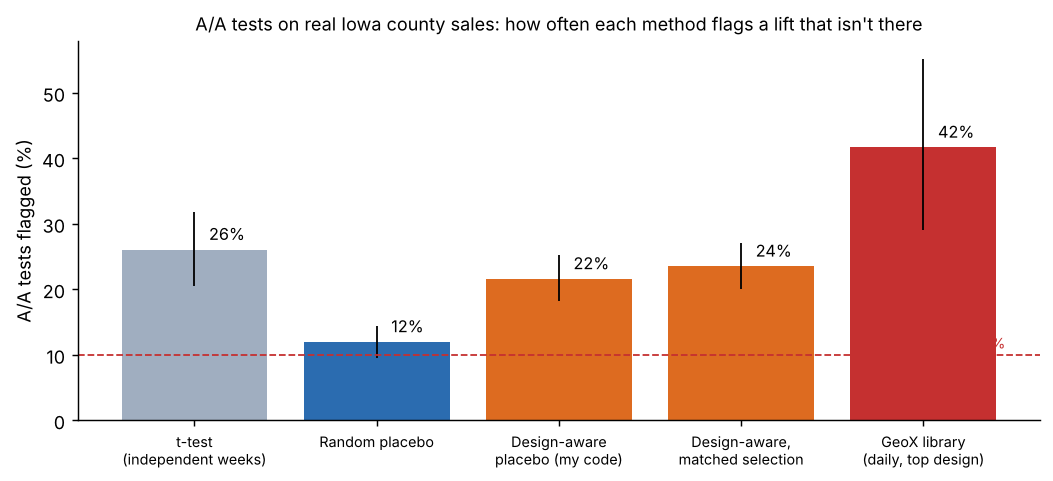

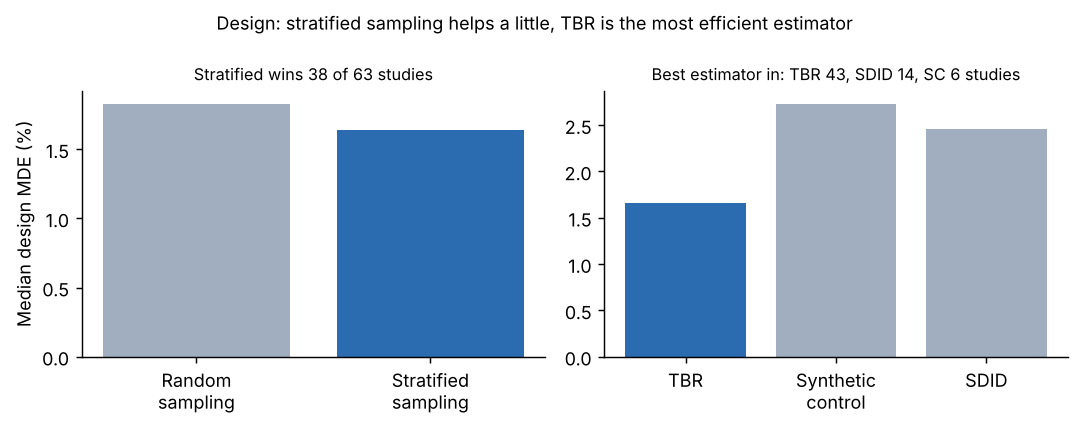

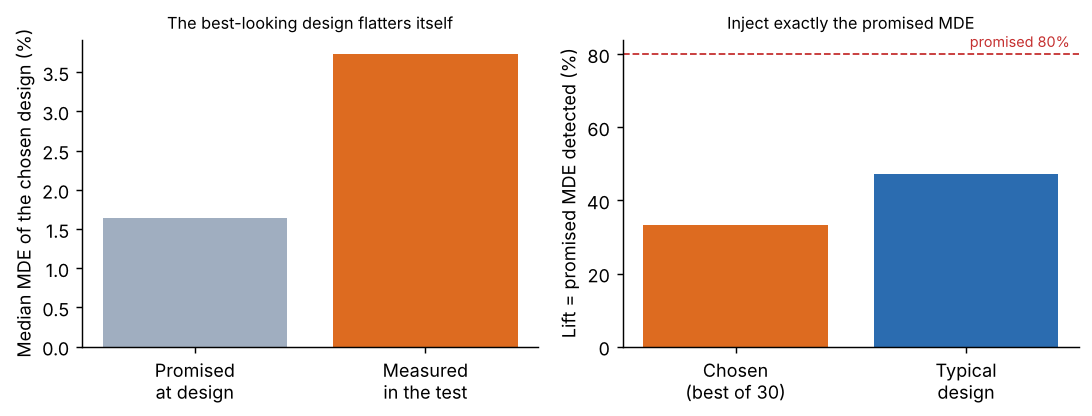

In [9]:
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREY, RED = "#2b6cb0", "#dd6b20", "#a0aec0", "#c53030"

fig, ax = plt.subplots(figsize=(8.2, 3.8))
labs = ["t-test\n(independent weeks)", "Random placebo", "Design-aware\nplacebo (my code)", "Design-aware,\nmatched selection", "GeoX library\n(daily, top design)"]
vals = [RES["H3"]["pooled"]["p_t"], RES["H3"]["pooled"]["p_rand"], RES["H3"]["pooled"]["p_da"], RES["explore"]["fpr_matched"], RES["library"]["fpr"]]
cis = [RES["H3"]["ci"]["p_t"], RES["H3"]["ci"]["p_rand"], RES["H3"]["ci"]["p_da"], RES["explore"]["ci_matched"], RES["library"]["fpr_ci"]]
ax.bar(range(5), np.array(vals) * 100, color=[GREY, BLUE, ORANGE, ORANGE, RED])
for k, (v, c) in enumerate(zip(vals, cis)):
    ax.vlines(k, c[0] * 100, c[1] * 100, color="black", lw=1)
    ax.text(k + 0.08, v * 100 + 1.5, f"{v*100:.0f}%", fontsize=9)
ax.axhline(10, color=RED, ls="--", lw=1); ax.text(4.45, 11, "target 10%", color=RED, ha="right", fontsize=8)
ax.set_xticks(range(5)); ax.set_xticklabels(labs, fontsize=8); ax.set_ylabel("A/A tests flagged (%)")
ax.set_title("A/A tests on real Iowa county sales: how often each method flags a lift that isn't there", fontsize=10)
fig.tight_layout(); fig.savefig("figures/fig1_false_positives.png", dpi=200)

fig, axs = plt.subplots(1, 2, figsize=(8.5, 3.3))
axs[0].bar(["Random\nsampling", "Stratified\nsampling"], [RES["H1"]["median_mde_random"] * 100, RES["H1"]["median_mde_strat"] * 100], color=[GREY, BLUE])
axs[0].set_ylabel("Median design MDE (%)"); axs[0].set_title(f"Stratified wins {RES['H1']['strat_wins']} of {RES['H1']['n']} studies", fontsize=9)
m = RES["H2"]["median_mde"]
axs[1].bar(["TBR", "Synthetic\ncontrol", "SDID"], [m["tbr"] * 100, m["sc"] * 100, m["sdid"] * 100], color=[BLUE, GREY, GREY])
bc = RES["H2"]["best_counts"]
axs[1].set_title(f"Best estimator in: TBR {bc.get('tbr',0)}, SDID {bc.get('sdid',0)}, SC {bc.get('sc',0)} studies", fontsize=9)
fig.suptitle("Design: stratified sampling helps a little, TBR is the most efficient estimator", fontsize=10); fig.tight_layout()
fig.savefig("figures/fig2_design.png", dpi=200)

fig, axs = plt.subplots(1, 2, figsize=(8.5, 3.3))
axs[0].bar(["Promised\nat design", "Measured\nin the test"], [RES["H6"]["chosen_median_mde_design"] * 100, RES["H6"]["chosen_median_mde_analysis"] * 100], color=[GREY, ORANGE])
axs[0].set_ylabel("Median MDE of the chosen design (%)"); axs[0].set_title("The best-looking design flatters itself", fontsize=9)
axs[1].bar(["Chosen\n(best of 30)", "Typical\ndesign"], [RES["H6"]["chosen_detect"] * 100, RES["H6"]["aa_detect"] * 100], color=[ORANGE, BLUE])
axs[1].axhline(80, color=RED, ls="--", lw=1); axs[1].text(1.45, 82, "promised 80%", color=RED, ha="right", fontsize=8)
axs[1].set_ylabel("Lift = promised MDE detected (%)"); axs[1].set_title("Inject exactly the promised MDE", fontsize=9)
fig.tight_layout(); fig.savefig("figures/fig3_mde_promise.png", dpi=200)

def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
json.dump(clean(RES), open("figures/results.json", "w"), indent=1)